# 1 — Dataset structure and paths

In [9]:
from pathlib import Path
import pandas as pd
from PIL import Image
import matplotlib.pyplot as plt
import seaborn as sns
import shutil
from sklearn.model_selection import train_test_split
import cv2

cwd = Path.cwd()
root = cwd.parent
data_dir = root / "data"

for folder in data_dir.iterdir():
    print(f"{folder}: ")
    for directory in folder.iterdir():
        print("\t",directory.name)

/home/walid/Documents/BrainScan_v2/data/Data: 
	 glioma
	 meningioma
	 pituitary
	 notumor


# 2 — Image integrity and format validation

In [10]:
origin_data = data_dir / "Data"

extensions = (".jpg",".jpeg",".png",".bmp")

supported = []
unsupported = []
unreadable = []
readable = []

for folder in origin_data.iterdir():
    for file in folder.iterdir():
        if file.name.lower().endswith(extensions):
            supported.append(file)
        else :
            unsupported.append(file)

def is_corrupted(path):
    try :
        with Image.open(path) as img :
            img.verify()
        return False
    except (IOError , SyntaxError) as e :
        return True

for path in supported :
    if is_corrupted(path) :
        unreadable.append(path)
    else :
        readable.append(path)


print("===============================")
print("         Dataset Summary       ")
print("===============================")
print(f"Supported images : {len(supported)}")
print(f"Unsupported images : {len(unsupported)}")
print(f"Readable images : {len(readable)}")
print(f"Unreadable images : {len(unreadable)}")
print("===============================")


data = {}

Filenames = []
widths = []
heights = []
channels = []

for file in readable :
    img = cv2.imread(file,cv2.IMREAD_UNCHANGED)
    shape = img.shape
    width = shape[0]
    height = shape[1]
    channel = shape[2] if len(shape) > 2 else 1

    Filenames.append(file.name)
    widths.append(width)
    heights.append(height)
    channels.append(channel)

data["Filename"] = Filenames
data["Width"] = widths
data["Height"] = heights
data["Channels"] = channels

df = pd.DataFrame(data)
display(df)

         Dataset Summary       
Supported images : 7023
Unsupported images : 0
Readable images : 7023
Unreadable images : 0


,Filename,Width,Height,Channels
0,Tr-gl_1275.jpg,512,512,1
1,Tr-gl_0835.jpg,512,512,1
2,Tr-gl_0549.jpg,512,512,1
3,Tr-gl_0253.jpg,512,512,1
4,Tr-gl_0874.jpg,512,512,1
...,...,...,...,...
7018,Tr-no_0012.jpg,630,630,3
7019,Tr-no_1183.jpg,262,236,3
7020,Tr-no_0018.jpg,442,332,3
7021,Tr-no_0404.jpg,630,630,3


# 4 - Visualizing Class Distribution

 GLIOMA : 1621
 MENINGIOMA : 1645
 NOTUMOR : 2000
 PITUITARY : 1757


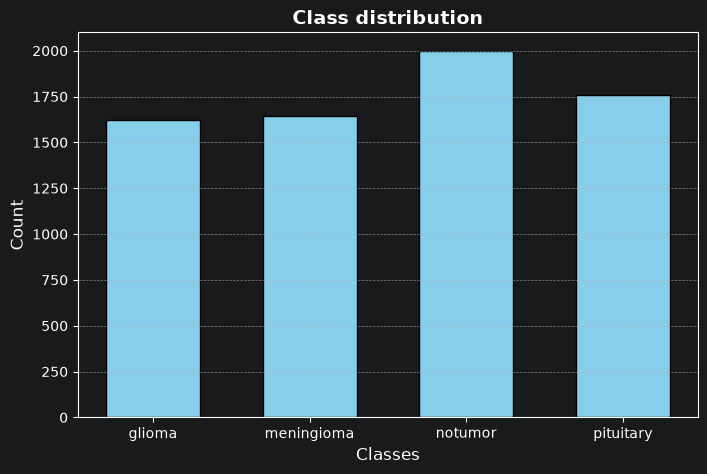

In [11]:
classes = {
    "glioma" : [],
    "meningioma" : [],
    "notumor" : [],
    "pituitary" : []
}

for folder in origin_data.iterdir():
    for file in folder.iterdir():
        classes[folder.name].append(file)

for key,value in classes.items():
    print(f" {key.upper()} : {len(value)}")

data = {
    "classes" : ["glioma","meningioma","notumor","pituitary"],
    "count" : [len(classes["glioma"]) , len(classes["meningioma"]) ,len(classes["notumor"]) ,
len(classes["pituitary"])]
}

plt.figure(figsize=(8, 5))

plt.bar(data["classes"], data["count"], color='skyblue', edgecolor='black', width=0.6)

plt.title('Class distribution', fontsize=14, fontweight='bold')
plt.xlabel('Classes', fontsize=12)
plt.ylabel('Count', fontsize=12)
plt.grid(axis='y', linestyle='--', alpha=0.7)

plt.show()

# 5 - Splitting Dataset to Classification part

In [13]:
def split_dataset(valid_images_by_class, dest_root):
    if dest_root.exists():
        shutil.rmtree(dest_root)

    for cls, images in valid_images_by_class.items():
        train, temp = train_test_split(images, test_size=0.30, random_state=42)
        val, test = train_test_split(temp, test_size=0.50, random_state=42)

        for name, files in [("train", train), ("val", val), ("test", test)]:
            folder = dest_root / name / cls
            folder.mkdir(parents=True, exist_ok=True)
            for f in files:
                shutil.copy2(f, folder / Path(f).name)

    return dest_root

valid_images_by_class = classes

dest_root = data_dir / "Classification"

split_path = split_dataset(valid_images_by_class, dest_root)

print(f"Dataset created at: {split_path}")



Dataset created at: /home/walid/Documents/BrainScan_v2/data/Classification
